<a href="https://colab.research.google.com/github/Tri8505/ML-Assignment-Adult-Census/blob/main/notebooks/pipeline_colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Cell 1 — Tải phiên bản mã nguồn và cài thư viện


In [1]:
from pathlib import Path
import os
import subprocess
import sys

REPO_URL = "https://github.com/Tri8505/ML-Assignment-Adult-Census.git"
SOURCE_REF = "a4f0284001990f904fea66953877e1dfc0681c49"
PROJECT_DIR = Path("/content") / f"ML-Assignment-Adult-Census-{SOURCE_REF[:8]}"

if not PROJECT_DIR.exists():
    subprocess.run(["git", "clone", REPO_URL, str(PROJECT_DIR)], check=True)
    subprocess.run(
        ["git", "-C", str(PROJECT_DIR), "checkout", "--detach", SOURCE_REF],
        check=True,
    )

source_commit = subprocess.check_output(
    ["git", "-C", str(PROJECT_DIR), "rev-parse", "HEAD"],
    text=True,
).strip()
assert source_commit == SOURCE_REF, "Sai phiên bản mã nguồn."

os.chdir(PROJECT_DIR)
if str(PROJECT_DIR) not in sys.path:
    sys.path.insert(0, str(PROJECT_DIR))

subprocess.run(
    [sys.executable, "-m", "pip", "install", "-q", "-r", "requirements.txt"],
    check=True,
)

print("Thư mục:", PROJECT_DIR)
print("Commit:", source_commit)

Thư mục: /content/ML-Assignment-Adult-Census-a4f02840
Commit: a4f0284001990f904fea66953877e1dfc0681c49


## Cell 2 — Import, cấu hình và tải dữ liệu


In [2]:
import json
import platform
import numpy as np
import pandas as pd
import sklearn
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

from modules.data_loader import load_adult_data
from modules.eda import run_eda
from modules.preprocessor import prepare_xy, export_features
from modules.traditional_models import (
    run_baselines,
    run_model_comparison,
    run_preprocessing_comparison,
    tune_random_forest,
    summarize_search,
    evaluate_test,
)

SEED = 42
results_dir = PROJECT_DIR / "reports" / "results"
figure_dir = PROJECT_DIR / "reports" / "figures"
feature_dir = PROJECT_DIR / "features"

for directory in (results_dir, figure_dir, feature_dir):
    directory.mkdir(parents=True, exist_ok=True)

environment_info = {
    "source_commit": source_commit,
    "seed": SEED,
    "python": platform.python_version(),
    "numpy": np.__version__,
    "pandas": pd.__version__,
    "scikit_learn": sklearn.__version__,
    "matplotlib": matplotlib.__version__,
    "seaborn": sns.__version__,
}

with (results_dir / "environment.json").open("w", encoding="utf-8") as file:
    json.dump(environment_info, file, ensure_ascii=False, indent=2)

train_df, test_df = load_adult_data()

assert train_df.shape == (32561, 15)
assert test_df.shape == (16281, 15)
for frame in (train_df, test_df):
    assert frame["income"].notna().all()
    assert set(frame["income"].unique()) == {"<=50K", ">50K"}

print("Train:", train_df.shape)
print("Test:", test_df.shape)
display(train_df.head())

Train: (32561, 15)
Test: (16281, 15)


,age,workclass,fnlwgt,education,education_num,marital_status,occupation,relationship,race,sex,capital_gain,capital_loss,hours_per_week,native_country,income
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K


## Cell 3 — EDA trên tập train


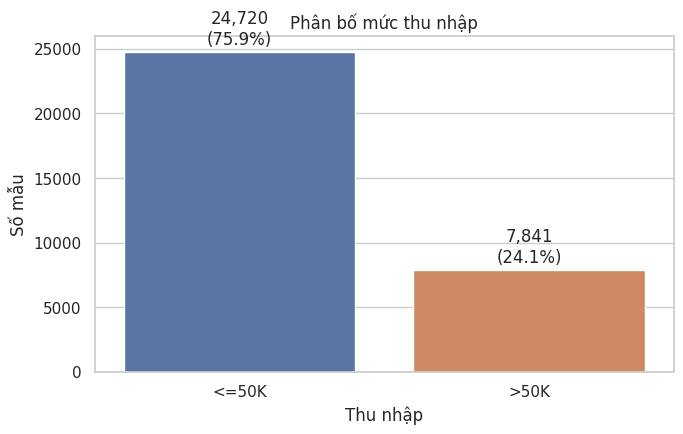

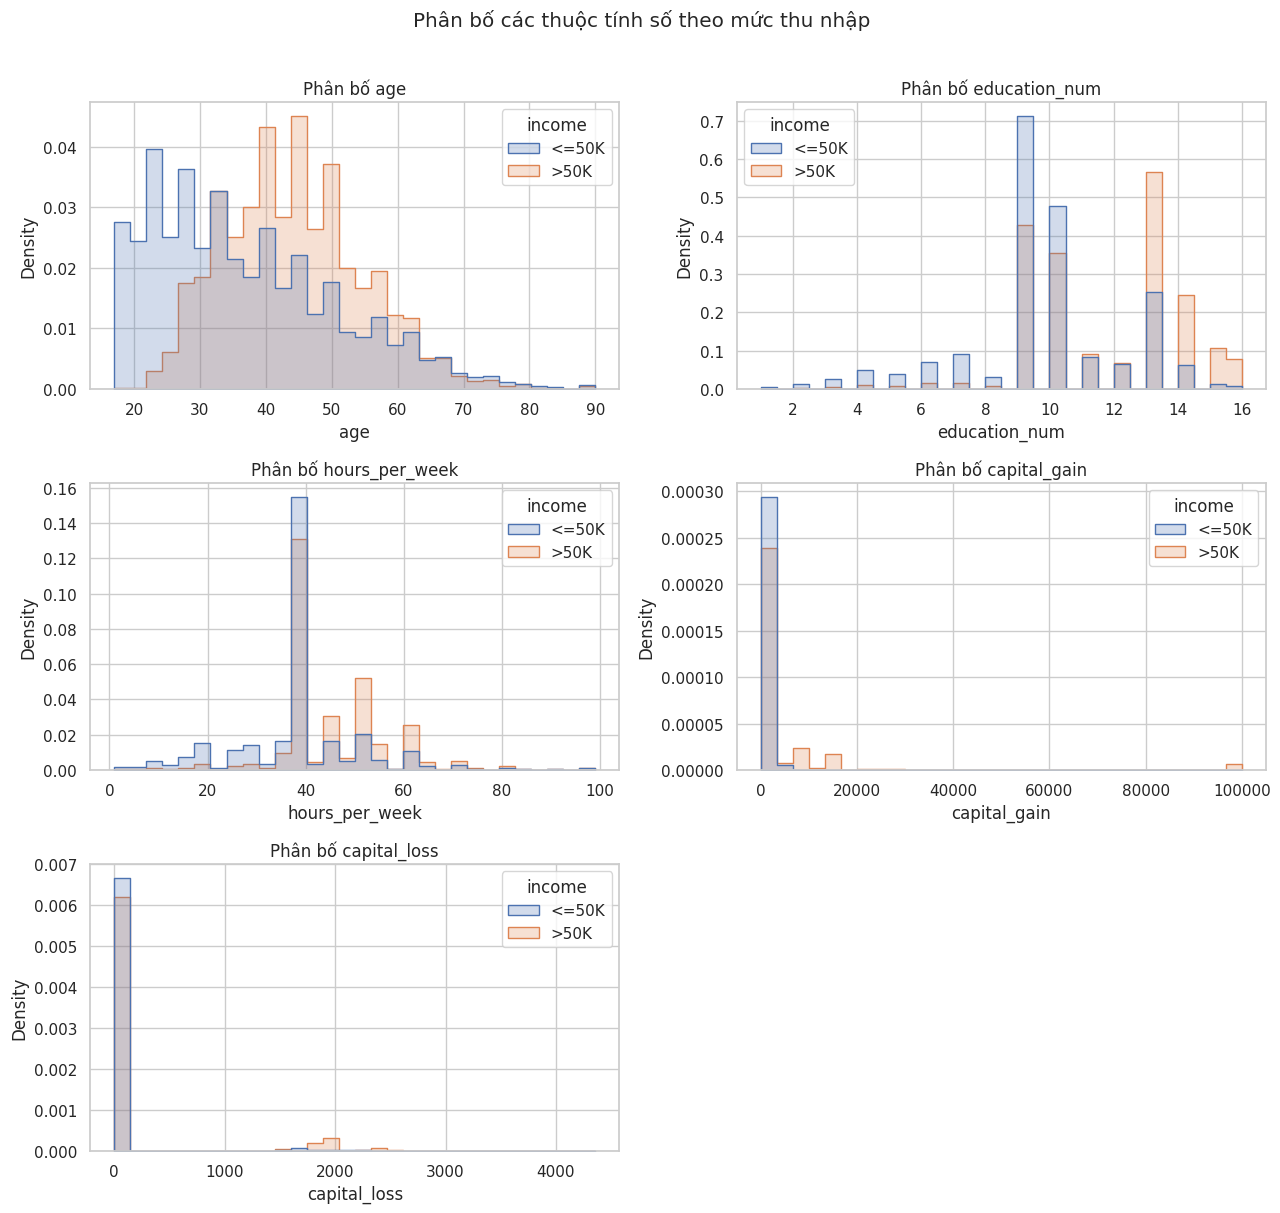

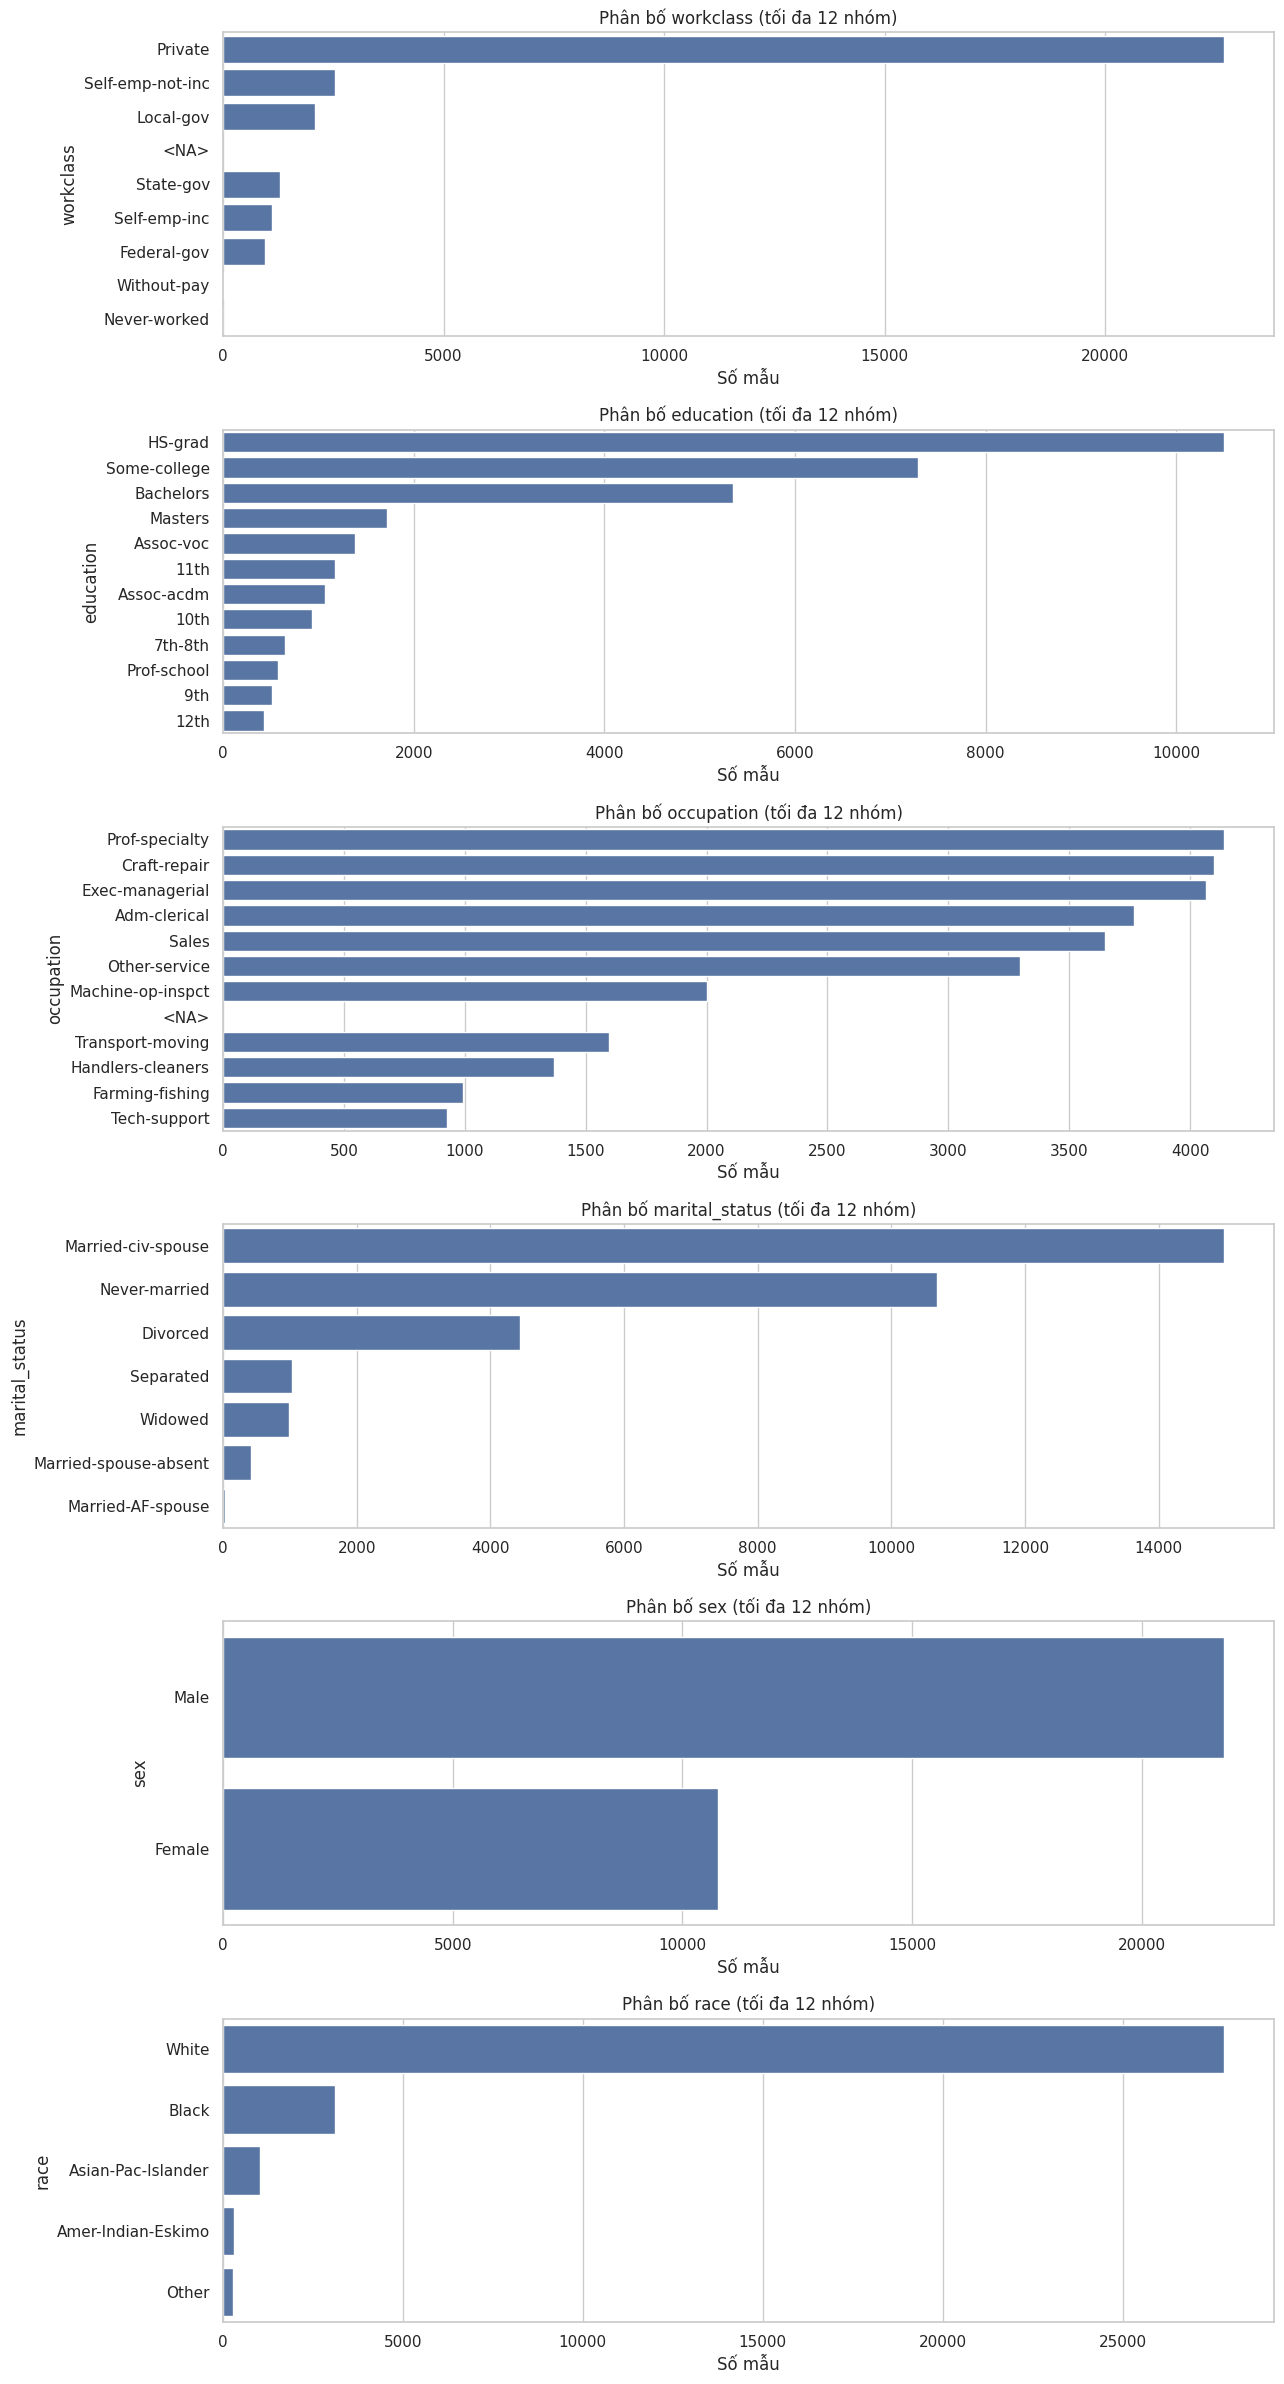

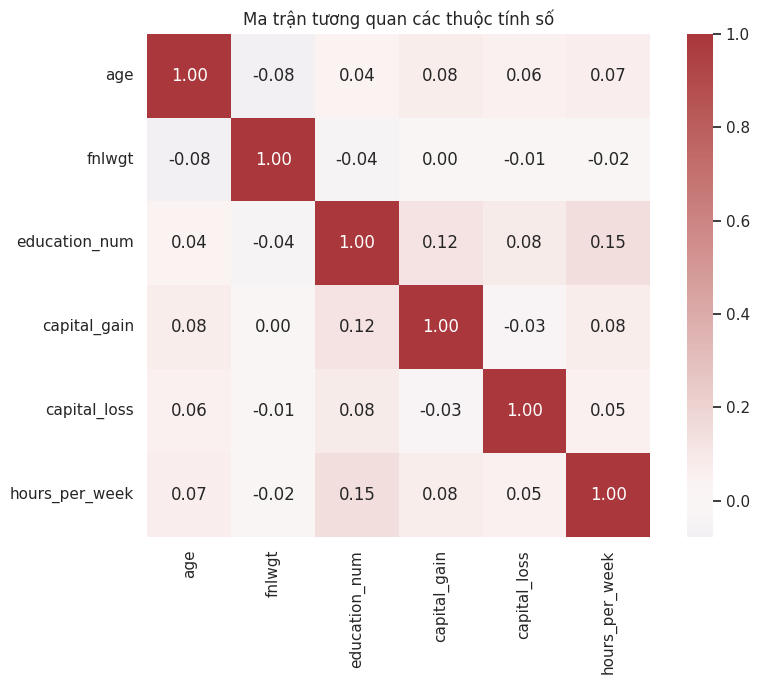

Kích thước: (32561, 15)
Số dòng trùng: 24

data_types


,dtype
age,int64
workclass,string
fnlwgt,int64
education,string
education_num,int64
marital_status,string
occupation,string
relationship,string
race,string
sex,string



missing_values


,missing_count,missing_percent
occupation,1843,5.660146
workclass,1836,5.638647
native_country,583,1.790486
age,0,0.000000
fnlwgt,0,0.000000
education,0,0.000000
education_num,0,0.000000
marital_status,0,0.000000
relationship,0,0.000000
race,0,0.000000



target_distribution


,count,percent
income,,
<=50K,24720,75.919044
>50K,7841,24.080956



numeric_summary


,count,mean,std,min,25%,50%,75%,max
age,32561.0,38.581647,13.640433,17.0,28.0,37.0,48.0,90.0
fnlwgt,32561.0,189778.366512,105549.977697,12285.0,117827.0,178356.0,237051.0,1484705.0
education_num,32561.0,10.080679,2.572720,1.0,9.0,10.0,12.0,16.0
capital_gain,32561.0,1077.648844,7385.292085,0.0,0.0,0.0,0.0,99999.0
capital_loss,32561.0,87.303830,402.960219,0.0,0.0,0.0,0.0,4356.0
hours_per_week,32561.0,40.437456,12.347429,1.0,40.0,40.0,45.0,99.0



categorical_summary


,count,unique,top,freq
workclass,30725,8,Private,22696
education,32561,16,HS-grad,10501
marital_status,32561,7,Married-civ-spouse,14976
occupation,30718,14,Prof-specialty,4140
relationship,32561,6,Husband,13193
race,32561,5,White,27816
sex,32561,2,Male,21790
native_country,31978,41,United-States,29170
income,32561,2,<=50K,24720


In [3]:
overview, figures = run_eda(
    train_df,
    output_dir=figure_dir,
    show=True,
)

print("Kích thước:", overview["shape"])
print("Số dòng trùng:", overview["duplicate_rows"])

for name in [
    "data_types",
    "missing_values",
    "target_distribution",
    "numeric_summary",
    "categorical_summary",
]:
    print("\n" + name)
    display(overview[name])
    overview[name].to_csv(results_dir / f"eda_{name}.csv")

pd.DataFrame([{
    "n_rows": train_df.shape[0],
    "n_columns": train_df.shape[1],
    "duplicate_rows": overview["duplicate_rows"],
}]).to_csv(results_dir / "eda_overview.csv", index=False)

## Cell 4 — Chuẩn bị X và y


In [4]:
X_train, y_train = prepare_xy(train_df)

print("X_train:", X_train.shape)
print("y_train:", y_train.shape)
print("Cột số:", X_train.select_dtypes(include="number").columns.tolist())
print("Cột phân loại:", X_train.select_dtypes(include="object").columns.tolist())
display(y_train.value_counts(normalize=True).rename("proportion"))

X_train: (32561, 14)
y_train: (32561,)
Cột số: ['age', 'fnlwgt', 'education_num', 'capital_gain', 'capital_loss', 'hours_per_week']
Cột phân loại: ['workclass', 'education', 'marital_status', 'occupation', 'relationship', 'race', 'sex', 'native_country']


,proportion
income,
0,0.75919
1,0.24081


## Cell 5 — Baseline


In [5]:
baseline_results = run_baselines(X_train, y_train, seed=SEED)
display(baseline_results.round(4))

baseline_results.to_csv(
    results_dir / "baseline_cv.csv",
    index=False,
)

Running: Dummy
Running: Logistic Regression


,model,cv_accuracy,cv_f1_macro,cv_f1_macro_std,cv_f1_>50K,cv_precision_>50K,cv_recall_>50K,train_f1_macro,mean_fit_seconds,f1_macro_gap
0,Logistic Regression,0.8505,0.7810,0.0018,0.6575,0.7335,0.5958,0.7837,1.1089,0.0027
1,Dummy,0.7592,0.4316,0.0000,0.0000,0.0000,0.0000,0.4316,0.1083,-0.0000


## Cell 6 — So sánh các mô hình


In [6]:
comparison_results = run_model_comparison(
    X_train, y_train, baseline_results, seed=SEED
)
display(comparison_results.round(4))

comparison_results.to_csv(
    results_dir / "model_comparison_cv.csv",
    index=False,
)

Running: Random Forest
Running: LinearSVC
Running: Logistic Regression balanced


,model,cv_accuracy,cv_f1_macro,cv_f1_macro_std,cv_f1_>50K,cv_precision_>50K,cv_recall_>50K,train_f1_macro,mean_fit_seconds,f1_macro_gap
0,Random Forest,0.8649,0.8015,0.0012,0.6893,0.7727,0.6221,0.8643,5.7092,0.0628
1,Logistic Regression,0.8505,0.7810,0.0018,0.6575,0.7335,0.5958,0.7837,1.1089,0.0027
2,LinearSVC,0.8506,0.7791,0.0014,0.6534,0.7403,0.5847,0.7824,0.3216,0.0033
3,Logistic Regression balanced,0.8092,0.7724,0.0024,0.6809,0.5701,0.8452,0.7752,0.9020,0.0028
4,Dummy,0.7592,0.4316,0.0000,0.0000,0.0000,0.0000,0.4316,0.1083,-0.0000


## Cell 7 — So sánh tiền xử lý và PCA


In [7]:
preprocessing_results = run_preprocessing_comparison(
    X_train, y_train, baseline_results, seed=SEED
)
display(preprocessing_results.round(4))

preprocessing_results.to_csv(
    results_dir / "preprocessing_comparison_cv.csv",
    index=False,
)

Running: LR + MinMax (0,1)
Running: LR + MinMax (-1,1)
Running: LR + Unknown imputation
Running: LR + PCA 90%
Running: LR + PCA 95%


,model,cv_accuracy,cv_f1_macro,cv_f1_macro_std,cv_f1_>50K,cv_precision_>50K,cv_recall_>50K,train_f1_macro,mean_fit_seconds,f1_macro_gap,delta_f1_vs_baseline
0,LR + Unknown imputation,0.8514,0.7828,0.0025,0.6608,0.7338,0.6011,0.7858,0.8272,0.0030,0.0019
1,LR baseline: Standard + mode,0.8505,0.7810,0.0018,0.6575,0.7335,0.5958,0.7837,1.1089,0.0027,0.0000
2,"LR + MinMax (-1,1)",0.8496,0.7793,0.0019,0.6548,0.7318,0.5925,0.7824,1.2558,0.0031,-0.0016
3,"LR + MinMax (0,1)",0.8484,0.7773,0.0013,0.6515,0.7297,0.5884,0.7804,1.1851,0.0031,-0.0036
4,LR + PCA 95%,0.8481,0.7762,0.0015,0.6493,0.7313,0.5839,0.7768,0.5922,0.0006,-0.0048
5,LR + PCA 90%,0.8455,0.7710,0.0010,0.6403,0.7284,0.5712,0.7726,1.2461,0.0017,-0.0100


## Cell 8 — Tuning Random Forest và chốt mô hình


In [8]:
rf_search = tune_random_forest(X_train, y_train, seed=SEED)
rf_tuning_results = summarize_search(rf_search)
final_model = rf_search.best_estimator_

display(rf_tuning_results.round(4))
print("Tham số tốt nhất:", rf_search.best_params_)
print(f"CV F1-macro tốt nhất: {rf_search.best_score_:.4f}")

original_rf_f1 = comparison_results.loc[
    comparison_results["model"] == "Random Forest", "cv_f1_macro"
].iloc[0]
print(f"Chênh lệch với RF ban đầu: {rf_search.best_score_ - original_rf_f1:+.4f}")

rf_tuning_results.to_csv(
    results_dir / "rf_tuning_summary.csv", index=False
)
pd.DataFrame(rf_search.cv_results_).to_csv(
    results_dir / "rf_tuning_full.csv", index=False
)

with (results_dir / "selected_model.json").open("w", encoding="utf-8") as file:
    json.dump({
        "model": "RandomForestClassifier",
        "selection_metric": "3-fold CV F1-macro",
        "best_params": rf_search.best_params_,
        "n_estimators": final_model.named_steps["classifier"].n_estimators,
        "best_cv_f1_macro": float(rf_search.best_score_),
        "seed": SEED,
    }, file, ensure_ascii=False, indent=2)

Fitting 3 folds for each of 12 candidates, totalling 36 fits


,rank,imputation,max_depth,min_samples_leaf,cv_accuracy,cv_f1_macro,cv_f1_macro_std,cv_f1_>50K,cv_precision_>50K,cv_recall_>50K,train_f1_macro,mean_fit_seconds,f1_macro_gap
0,1,most_frequent,None,2,0.8649,0.8015,0.0012,0.6893,0.7727,0.6221,0.8643,4.7809,0.0628
1,2,constant,None,2,0.8641,0.8001,0.0017,0.6869,0.7714,0.6192,0.8649,5.6839,0.0649
2,3,most_frequent,20,2,0.8634,0.7959,0.0014,0.6785,0.7829,0.5986,0.8365,5.5233,0.0406
3,4,constant,20,2,0.8628,0.7943,0.0008,0.6757,0.7841,0.5937,0.8343,4.5898,0.0399
4,5,constant,None,5,0.8620,0.7943,0.0021,0.6763,0.7772,0.5986,0.8180,4.2681,0.0237
5,6,most_frequent,None,5,0.8617,0.7938,0.0015,0.6755,0.7766,0.5976,0.8175,4.4018,0.0237
6,7,most_frequent,20,5,0.8610,0.7909,0.0029,0.6697,0.7829,0.5851,0.8089,4.0942,0.0181
7,8,constant,20,5,0.8604,0.7898,0.0025,0.6681,0.7816,0.5833,0.8084,4.3388,0.0186
8,9,most_frequent,12,2,0.8592,0.7841,0.0021,0.6567,0.7949,0.5595,0.7990,4.0103,0.0150
9,10,constant,12,2,0.8581,0.7818,0.0026,0.6528,0.7949,0.5539,0.7988,6.3488,0.0169


Tham số tốt nhất: {'classifier__max_depth': None, 'classifier__min_samples_leaf': 2, 'preprocessor__categorical__imputer__strategy': 'most_frequent'}
CV F1-macro tốt nhất: 0.8015
Chênh lệch với RF ban đầu: +0.0000


## Cell 9 — Đánh giá cuối trên tập test


In [9]:
X_test, y_test = prepare_xy(
    test_df, feature_columns=X_train.columns
)

test_results, report_dict, y_pred = evaluate_test(
    final_model, X_test, y_test
)

display(test_results.round(4))
display(pd.DataFrame(report_dict).T.round(4))

test_results.to_csv(
    results_dir / "final_test_metrics.csv", index=False
)
pd.DataFrame(report_dict).T.to_csv(
    results_dir / "final_classification_report.csv"
)

,model,test_accuracy,test_f1_macro,test_f1_>50K,test_precision_>50K,test_recall_>50K,test_roc_auc,test_average_precision
0,Selected Random Forest,0.8628,0.7949,0.6768,0.7633,0.6079,0.9149,0.7965


,precision,recall,f1-score,support
<=50K,0.8859,0.9417,0.9130,12435.0000
>50K,0.7633,0.6079,0.6768,3846.0000
accuracy,0.8628,0.8628,0.8628,0.8628
macro avg,0.8246,0.7748,0.7949,16281.0000
weighted avg,0.8569,0.8628,0.8572,16281.0000


## Cell 10 — Confusion matrix


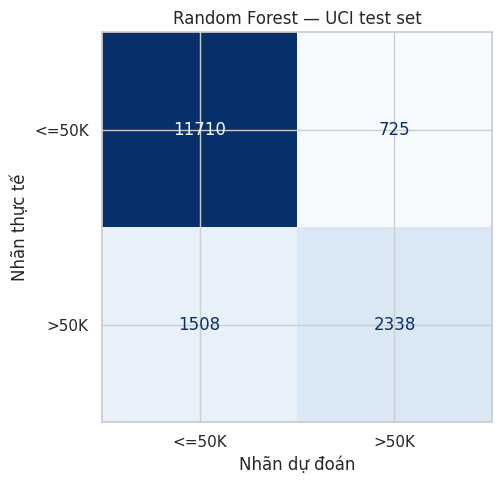

In [10]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

class_names = ["<=50K", ">50K"]
matrix = confusion_matrix(y_test, y_pred, labels=[0, 1])

pd.DataFrame(
    matrix,
    index=["actual_<=50K", "actual_>50K"],
    columns=["predicted_<=50K", "predicted_>50K"],
).to_csv(results_dir / "final_confusion_matrix.csv")

fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay(
    confusion_matrix=matrix,
    display_labels=class_names,
).plot(ax=ax, cmap="Blues", values_format="d", colorbar=False)

ax.set_title("Random Forest — UCI test set")
ax.set_xlabel("Nhãn dự đoán")
ax.set_ylabel("Nhãn thực tế")
fig.tight_layout()
fig.savefig(
    figure_dir / "final_confusion_matrix.png",
    dpi=160,
    bbox_inches="tight",
)
plt.show()

## Cell 11 — Xuất và kiểm tra đặc trưng


In [11]:
feature_summary = export_features(
    final_model.named_steps["preprocessor"],
    X_train, X_test, y_train, y_test,
    output_dir=feature_dir,
    metadata={
        "source": "https://archive.ics.uci.edu/dataset/2/adult",
        "source_commit": source_commit,
        "split": "Official UCI train/test split",
        "best_params": rf_search.best_params_,
        "n_estimators": final_model.named_steps["classifier"].n_estimators,
        "numeric_imputation": "median",
        "numeric_scaling": "StandardScaler",
        "categorical_encoding": "OneHotEncoder(handle_unknown='ignore')",
        "pca": None,
        "seed": SEED,
        "selection_metric": "3-fold CV F1-macro",
        "best_cv_f1_macro": float(rf_search.best_score_),
    },
)
display(feature_summary)
feature_summary.to_csv(
    results_dir / "feature_summary.csv", index=False
)

,file,shape,size_MiB
0,X_train_cfg1.npy,"(32561, 105)",26.084297
1,X_test_cfg1.npy,"(16281, 105)",13.042610
2,y_train.npy,"(32561,)",0.248543
3,y_test.npy,"(16281,)",0.124336


## Cell 12 — Đóng gói kết quả


In [13]:
from datetime import datetime, timezone
from zipfile import ZipFile, ZIP_DEFLATED

artifact_groups = {
    "features": {".npy", ".json"},
    "reports/results": {".csv", ".json"},
    "reports/figures": {".png"},
}

timestamp = datetime.now(timezone.utc).strftime("%Y%m%d_%H%M%S_%f")
archive_path = Path("/content") / f"adult_results_{timestamp}.zip"
included_files = []

with ZipFile(archive_path, "w", compression=ZIP_DEFLATED) as archive:
    for relative_dir, extensions in artifact_groups.items():
        source_dir = PROJECT_DIR / relative_dir
        for path in sorted(source_dir.rglob("*")):
            if path.is_file() and path.suffix.lower() in extensions:
                if path.stat().st_size == 0:
                    raise ValueError(f"File rỗng: {path}")
                relative_path = path.relative_to(PROJECT_DIR).as_posix()
                archive.write(path, arcname=relative_path)
                included_files.append(relative_path)

print(f"Đã đóng gói {len(included_files)} file.")
print("ZIP:", archive_path)
print(f"Dung lượng: {archive_path.stat().st_size / 1024**2:.2f} MiB")

DOWNLOAD_ZIP = False
if DOWNLOAD_ZIP:
    from google.colab import files
    files.download(str(archive_path))

Đã đóng gói 27 file.
ZIP: /content/adult_results_20261124_094951_234748.zip
Dung lượng: 2.13 MiB
